# 광각 YOLO 2단계 학습 · 평가

1단계는 합성 데이터로 처음부터 학습하고, 2단계는 실제 데이터만으로 미세조정한다. 마지막에 실제 test 로 평가한다.
설정은 모두 `configs/hyp.yaml` 에서 읽는다 (README '학습 설정').

| 단계 | 시작 가중치 | 데이터 | epoch | lr0 | 결과 폴더 |
|---|---|---|---|---|---|
| 1단계 (sim) | yolo26n.pt | 합성 train 2834 | 33 고정 (patience 0) | 0.001 | `runs/wide/sim_pre` |
| 2단계 (real) | 1단계 `last.pt` | 실제 train 490 / val 68 | 최대 60, patience 30 | 0.0005 | `runs/wide/real_ft` |

| 셀 | 내용 | 시간 (RTX 5060 Laptop) |
|---|---|---|
| 0 | 설정 | – |
| 1 | data.yaml 만들기 (`prepare_data.py`) | 몇 초 |
| 2 | 1단계 학습 | 약 20분 |
| 3 | 2단계 학습 | 약 5분 |
| 4 | 학습 곡선 | 몇 초 |
| 5 | 실제 test 평가 (전체 / 밝음 / 어두움, 클래스별) | 1~2분 |
| 6 | 혼동 행렬 (conf 0.5) | 몇 초 |
| 7 | test 사진 | 몇 초 |

준비: `datasets/sim`, `datasets/real` (README '데이터'). 결과 폴더가 이미 있으면 학습 셀은 건너뛴다.


## 0. 설정

In [1]:
import csv, os, subprocess, sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import yaml
from ultralytics.utils import LOGGER

plt.rcParams['font.family'] = ['NanumGothic', 'Noto Sans CJK KR', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
LOGGER.setLevel('WARNING')                     # 평가 때 ultralytics 진행 로그 숨김

HERE = Path.cwd().resolve()
WIDE_DIR = next(p for p in [HERE, *HERE.parents] if (p / 'scripts' / 'train.py').exists())   # yolo/wide
SCRIPTS, CONFIGS, DATA, RUNS = WIDE_DIR / 'scripts', WIDE_DIR / 'configs', WIDE_DIR / 'datasets', WIDE_DIR / 'runs' / 'wide'
sys.path.insert(0, str(SCRIPTS))
PY = sys.executable

HYP = yaml.safe_load((CONFIGS / 'hyp.yaml').read_text())
IMGSZ = HYP['common']['imgsz']
SIM_NAME, REAL_NAME = HYP['stages']['sim']['name'], HYP['stages']['real']['name']   # sim_pre, real_ft
REAL = DATA / 'real'
DARK = 60                                      # 이 밝기(0~255) 보다 어두우면 '어두운 사진'
CONF = 0.5                                     # planning 이 쓰는 conf


def short(s):
    """출력의 절대경로를 짧게 (yolo/wide 기준)"""
    return s.replace(str(WIDE_DIR), '<wide>').replace(str(Path.home()), '~')


def run(cmd):
    """scripts/ 에서 명령 실행, 출력을 셀에 바로 보여 줌"""
    print('$', short(' '.join(map(str, cmd))).replace(short(PY), 'python'), flush=True)
    p = subprocess.Popen([str(c) for c in cmd], cwd=SCRIPTS, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                         env={**os.environ, 'PYTHONUNBUFFERED': '1'})
    for line in iter(p.stdout.readline, b''):
        print(short(line.decode(errors='replace').split('\r')[-1]), end='', flush=True)
    if p.wait():
        raise RuntimeError(f'실패 (코드 {p.returncode})')


assert (DATA / 'sim').exists() and REAL.exists(), 'datasets/sim, datasets/real 이 필요함 (README 데이터)'
print(f'1단계 {SIM_NAME}: epoch {HYP["stages"]["sim"]["epochs"]}, patience {HYP["stages"]["sim"].get("patience")}, lr0 {HYP["stages"]["sim"]["lr0"]}')
print(f'2단계 {REAL_NAME}: 최대 epoch {HYP["stages"]["real"]["epochs"]}, patience {HYP["common"]["patience"]}, lr0 {HYP["stages"]["real"]["lr0"]}')


1단계 sim_pre: epoch 33, patience 0, lr0 0.001
2단계 real_ft: 최대 epoch 60, patience 30, lr0 0.0005


## 1. data.yaml 만들기
`configs/data_sim.yaml` (train 합성, val/test 실제), `configs/data_real.yaml` (모두 실제). 절대경로가 들어가서 커밋하지 않음

In [2]:
run([PY, 'prepare_data.py'])


$ python prepare_data.py
이미지 수: {'sim_train': 2834, 'sim_val': 392, 'sim_test': 374, 'real_train': 490, 'real_val': 68, 'real_test': 52}
data_sim.yaml: train ~/바탕화면/git/TIL/classes/PhysicalAi/projects/project-2/archive/team_yolo/yolo/datasets/sim_20261028/sim/images/train
  val ~/바탕화면/git/TIL/classes/PhysicalAi/projects/project-2/archive/team_yolo/yolo/datasets/real_v5/images/val
  test ~/바탕화면/git/TIL/classes/PhysicalAi/projects/project-2/archive/team_yolo/yolo/datasets/real_v5/images/test
data_real.yaml: train ~/바탕화면/git/TIL/classes/PhysicalAi/projects/project-2/archive/team_yolo/yolo/datasets/real_v5/images/train
  val ~/바탕화면/git/TIL/classes/PhysicalAi/projects/project-2/archive/team_yolo/yolo/datasets/real_v5/images/val
  test ~/바탕화면/git/TIL/classes/PhysicalAi/projects/project-2/archive/team_yolo/yolo/datasets/real_v5/images/test


## 2. 1단계: 합성만 33 epoch (약 20분)
val 로 best 를 고르지 않고 마지막 `last.pt` 를 2단계로 넘긴다. 실제 val 이 68장으로 작아서 best epoch 가 운에 따라 크게 바뀌기 때문

In [3]:
# 1단계: 합성만, 33 epoch 고정. 실제 val 은 곡선 보기용
if (RUNS / SIM_NAME / 'weights' / 'last.pt').exists():
    print(f'runs/wide/{SIM_NAME} 이 이미 있어서 건너뜀 (다시 하려면 폴더를 옮기거나 지울 것)')
else:
    run([PY, 'train.py', '--stage', 'sim'])


runs/wide/sim_pre 이 이미 있어서 건너뜀 (다시 하려면 폴더를 옮기거나 지울 것)


## 3. 2단계: 실제만 미세조정 (약 5분)

In [4]:
# 2단계: 1단계 last.pt 에서 실제 데이터만으로 미세조정. 실제 val 로 best.pt 를 고름
STAGE1 = RUNS / SIM_NAME / 'weights' / 'last.pt'
if (RUNS / REAL_NAME / 'weights' / 'best.pt').exists():
    print(f'runs/wide/{REAL_NAME} 이 이미 있어서 건너뜀')
else:
    run([PY, 'train.py', '--stage', 'real', '--weights', STAGE1])


runs/wide/real_ft 이 이미 있어서 건너뜀


## 4. 학습 곡선
위: 실제 val mAP. 아래: train / val 손실. 1단계에서 train(합성) 손실은 내려가는데 val(실제) 손실이 안 내려가면 합성과 실제의 차이(도메인 차이)

1단계: 33 epoch, 마지막 실제 val mAP50 0.824 / mAP50-95 0.641
2단계: 37 epoch, best ep7 실제 val mAP50 0.968 / mAP50-95 0.838


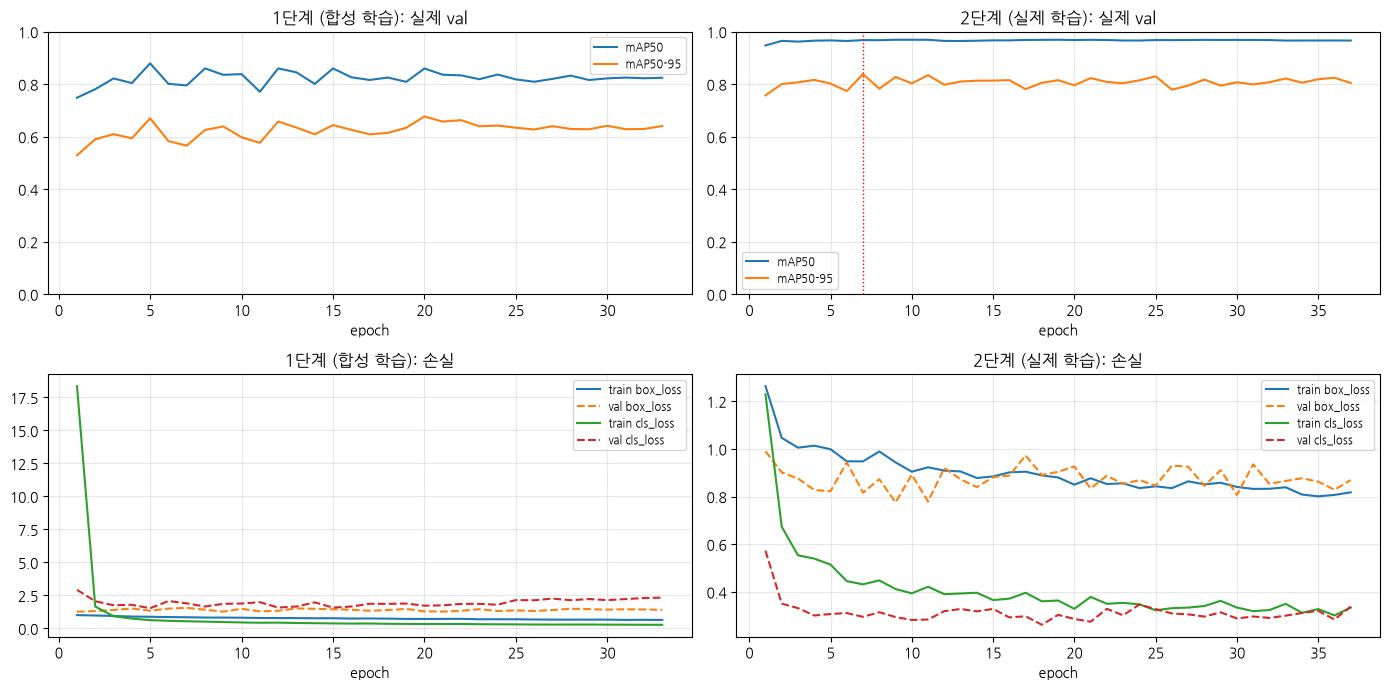

2단계 빨간 점선 = best epoch (이 가중치가 best.pt)


In [5]:
def read_results(run_dir):
    with open(Path(run_dir) / 'results.csv') as f:
        rows = list(csv.DictReader(f))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}


def fitness(r):
    return 0.1 * r['metrics/mAP50(B)'] + 0.9 * r['metrics/mAP50-95(B)']


s1, s2 = read_results(RUNS / SIM_NAME), read_results(RUNS / REAL_NAME)
b2 = int(np.argmax(fitness(s2)))
print(f'1단계: {len(s1["epoch"])} epoch, 마지막 실제 val mAP50 {s1["metrics/mAP50(B)"][-1]:.3f} / mAP50-95 {s1["metrics/mAP50-95(B)"][-1]:.3f}')
print(f'2단계: {len(s2["epoch"])} epoch, best ep{int(s2["epoch"][b2])} 실제 val mAP50 {s2["metrics/mAP50(B)"][b2]:.3f} / mAP50-95 {s2["metrics/mAP50-95(B)"][b2]:.3f}')

fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for col, (title, r) in enumerate((('1단계 (합성 학습)', s1), ('2단계 (실제 학습)', s2))):
    ax = axes[0, col]
    ax.plot(r['epoch'], r['metrics/mAP50(B)'], label='mAP50')
    ax.plot(r['epoch'], r['metrics/mAP50-95(B)'], label='mAP50-95')
    ax.set_title(f'{title}: 실제 val'); ax.set_ylim(0, 1)
    ax = axes[1, col]
    for k in ('box_loss', 'cls_loss'):
        ax.plot(r['epoch'], r[f'train/{k}'], label=f'train {k}')
        ax.plot(r['epoch'], r[f'val/{k}'], '--', label=f'val {k}')
    ax.set_title(f'{title}: 손실')
for ax in axes.flat:
    ax.set_xlabel('epoch'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
axes[0, 1].axvline(s2['epoch'][b2], color='red', ls=':', lw=1)
plt.tight_layout(); plt.show()
print('2단계 빨간 점선 = best epoch (이 가중치가 best.pt)')


## 5. 실제 test 평가
mAP 는 표준대로 conf 0.001. 밝기 60 미만을 어두움으로 따로 본다

실제 test 장수: {'전체': 52, '밝음': 43, '어두움': 9}

모델              구분         mAP50  mAP50-95      P      R
1단계 (합성만)       전체         0.597     0.383  0.620  0.612
1단계 (합성만)       밝음         0.658     0.407  0.627  0.677
1단계 (합성만)       어두움        0.554     0.390  0.992  0.500
2단계 (최종)        전체         0.949     0.705  0.887  0.891
2단계 (최종)        밝음         0.950     0.690  0.882  0.889
2단계 (최종)        어두움        0.995     0.823  0.988  0.966

클래스별 mAP50 (실제 test 전체)
클래스                  1단계 (합성만)        2단계 (최종)
red_cyl                  0.870           0.957
green_cyl                0.663           0.924
red_box                  0.454           0.961
green_box                0.105           0.891
barcode                  0.964           0.968
traffic_light            0.523           0.993


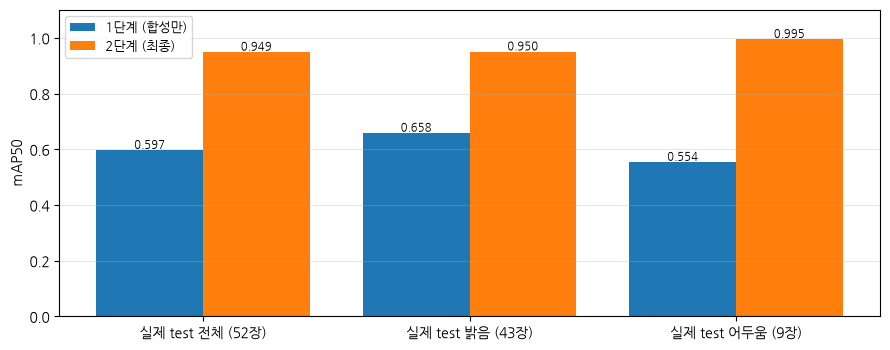

In [6]:
from ultralytics import YOLO
from val import CLASSES, run as val_run

WEIGHTS = {'1단계 (합성만)': RUNS / SIM_NAME / 'weights' / 'last.pt',
           '2단계 (최종)': RUNS / REAL_NAME / 'weights' / 'best.pt'}

rep = list(csv.DictReader(open(REAL / 'split_report.csv')))       # 사진별 밝기 (build_real_split.py)
bri = {r['image']: float(r['brightness']) for r in rep}
test_imgs = sorted((REAL / 'images' / 'test').glob('*.jpg'))
groups = {'전체': test_imgs,
          '밝음': [p for p in test_imgs if bri[p.name] >= DARK],
          '어두움': [p for p in test_imgs if bri[p.name] < DARK]}
EVAL = WIDE_DIR / 'runs' / 'eval'
EVAL.mkdir(parents=True, exist_ok=True)
yamls = {}
for g, ps in groups.items():
    lst = EVAL / f'test_{g}.txt'
    lst.write_text('\n'.join(map(str, ps)) + '\n')
    y = EVAL / f'test_{g}.yaml'
    y.write_text(f'train: {lst}\nval: {lst}\ntest: {lst}\nnc: {len(CLASSES)}\nnames: {CLASSES}\n')
    yamls[g] = y
print('실제 test 장수:', {g: len(ps) for g, ps in groups.items()})

table, per_class = {}, {}
for mname, w in WEIGHTS.items():
    model = YOLO(str(w))
    for g, y in yamls.items():
        m, rows = val_run(model, y, 'test', IMGSZ, f'{mname}_{g}', 0.001)
        table[(mname, g)] = (m.box.map50, m.box.map, m.box.mp, m.box.mr)
        if g == '전체':
            per_class[mname] = rows

models = list(WEIGHTS)
print(f'\n{"모델":<16}{"구분":<8}{"mAP50":>8}{"mAP50-95":>10}{"P":>7}{"R":>7}')
for (mname, g), (a50, a, p, r) in table.items():
    print(f'{mname:<16}{g:<8}{a50:8.3f}{a:10.3f}{p:7.3f}{r:7.3f}')

print('\n클래스별 mAP50 (실제 test 전체)')
print(f'{"클래스":<14}' + ''.join(f'{mn:>16}' for mn in models))
for cname in CLASSES:
    vals = []
    for mn in models:
        row = next((r for r in per_class[mn] if r[0] == cname), None)
        vals.append(f'{row[3]:16.3f}' if row else f'{"-":>16}')
    print(f'{cname:<14}' + ''.join(vals))

gs = list(yamls)
fig, ax = plt.subplots(figsize=(9, 3.6))
w = 0.8 / len(models)
for i, mn in enumerate(models):
    bars = ax.bar(np.arange(len(gs)) + i * w, [table[(mn, g)][0] for g in gs], w, label=mn)
    ax.bar_label(bars, fmt='%.3f', fontsize=8)
ax.set_xticks(np.arange(len(gs)) + w * (len(models) - 1) / 2, [f'실제 test {g} ({len(groups[g])}장)' for g in gs])
ax.set_ylim(0, 1.1); ax.set_ylabel('mAP50'); ax.legend(fontsize=9); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()


## 6. 혼동 행렬 (conf 0.5)
행 = 정답, 열 = 예측, 색 = 정답 행마다 비율. 마지막 열 '배경' = 놓침, 마지막 행 '배경' = 오검출. IoU 0.5 이상인 박스끼리 짝짓는다

findfont: Failed to find font weight bold for NanumGothic, now using 600.


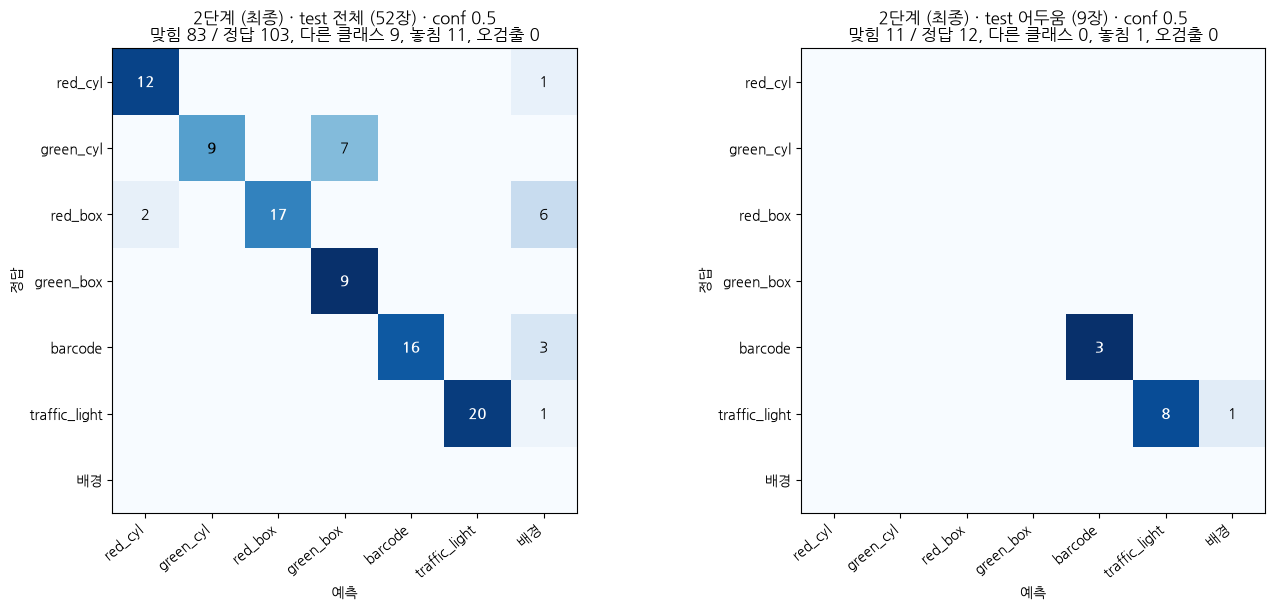

저장: runs/eval/confusion_conf05.png

헷갈린 것 (정답 → 예측, 개수)
  2단계 (최종) / 전체: green_cyl→green_box 7, red_box→배경 6, barcode→배경 3, red_box→red_cyl 2, traffic_light→배경 1, red_cyl→배경 1
  2단계 (최종) / 어두움: traffic_light→배경 1


In [7]:
# conf 0.5 혼동 행렬: 행 = 정답, 열 = 예측. IoU 0.5 이상인 박스끼리 짝지음 (클래스 상관없이 IoU 큰 순)
# 마지막 행/열 '배경': 정답이 있는데 못 찾음(놓침) = 열 '배경', 없는 곳에 예측(오검출) = 행 '배경'
CM_CONF, CM_IOU = CONF, 0.5
LABELS = CLASSES + ['배경']
nc = len(CLASSES)


def read_gt(img_path, w, h):
    lab = Path(str(img_path).replace('/images/', '/labels/')).with_suffix('.txt')
    out = []
    if lab.exists():
        for line in lab.read_text().splitlines():
            if line.strip():
                c_, cx, cy, bw, bh = map(float, line.split()[:5])
                out.append((int(c_), [(cx - bw / 2) * w, (cy - bh / 2) * h, (cx + bw / 2) * w, (cy + bh / 2) * h]))
    return out


def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter + 1e-9)


def confusion(model, imgs):
    cm = np.zeros((nc + 1, nc + 1), int)
    for r in model.predict([str(p) for p in imgs], conf=CM_CONF, imgsz=IMGSZ, verbose=False, stream=True):
        h, w = r.orig_shape
        gt = read_gt(r.path, w, h)
        pr = list(zip(r.boxes.cls.int().tolist(), r.boxes.xyxy.tolist()))
        pairs = sorted(((iou(g[1], p[1]), i, j) for i, g in enumerate(gt) for j, p in enumerate(pr)), reverse=True)
        used_g, used_p = set(), set()
        for v, i, j in pairs:
            if v < CM_IOU:
                break
            if i in used_g or j in used_p:
                continue
            used_g.add(i); used_p.add(j)
            cm[gt[i][0], pr[j][0]] += 1
        for i, g in enumerate(gt):
            if i not in used_g:
                cm[g[0], nc] += 1          # 놓침
        for j, p in enumerate(pr):
            if j not in used_p:
                cm[nc, p[0]] += 1          # 오검출
    return cm


cms = {}
models = ['2단계 (최종)']
for mname in models:
    model = YOLO(str(WEIGHTS[mname]))
    for g in ('전체', '어두움'):
        cms[(mname, g)] = confusion(model, groups[g])

fig, axes = plt.subplots(len(models), 2, figsize=(14, 6.2 * len(models)), squeeze=False)
for ax, ((mname, g), cm) in zip(axes.flat, cms.items()):
    rows = cm.sum(1, keepdims=True)
    norm = np.divide(cm, rows, out=np.zeros_like(cm, float), where=rows > 0)   # 정답 행마다 비율 (색)
    ax.imshow(norm, cmap='Blues', vmin=0, vmax=1)
    for i in range(nc + 1):
        for j in range(nc + 1):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=11,
                        color='white' if norm[i, j] > 0.6 else 'black', fontweight='bold' if i == j else 'normal')
    ax.set_xticks(range(nc + 1), LABELS, rotation=40, ha='right'); ax.set_yticks(range(nc + 1), LABELS)
    ax.set_xlabel('예측'); ax.set_ylabel('정답')
    tp = np.trace(cm[:nc, :nc])
    ax.set_title(f'{mname} · test {g} ({len(groups[g])}장) · conf {CM_CONF}\n'
                 f'맞힘 {tp} / 정답 {cm[:nc].sum()}, 다른 클래스 {cm[:nc, :nc].sum() - tp}, 놓침 {cm[:nc, nc].sum()}, 오검출 {cm[nc, :nc].sum()}')
plt.tight_layout()
out_png = EVAL / 'confusion_conf05.png'
plt.savefig(out_png, dpi=120); plt.show()
print('저장: runs/eval/confusion_conf05.png')

print('\n헷갈린 것 (정답 → 예측, 개수)')
for (mname, g), cm in cms.items():
    errs = [(cm[i, j], LABELS[i], LABELS[j]) for i in range(nc + 1) for j in range(nc + 1) if i != j and cm[i, j]]
    errs.sort(reverse=True)
    print(f'  {mname} / {g}:', ', '.join(f'{a}→{b} {n}' for n, a, b in errs) or '없음')

## 7. test 사진 (어두운 사진 먼저)
정답 = 초록(얇게), 예측 = 빨강, conf 0.5

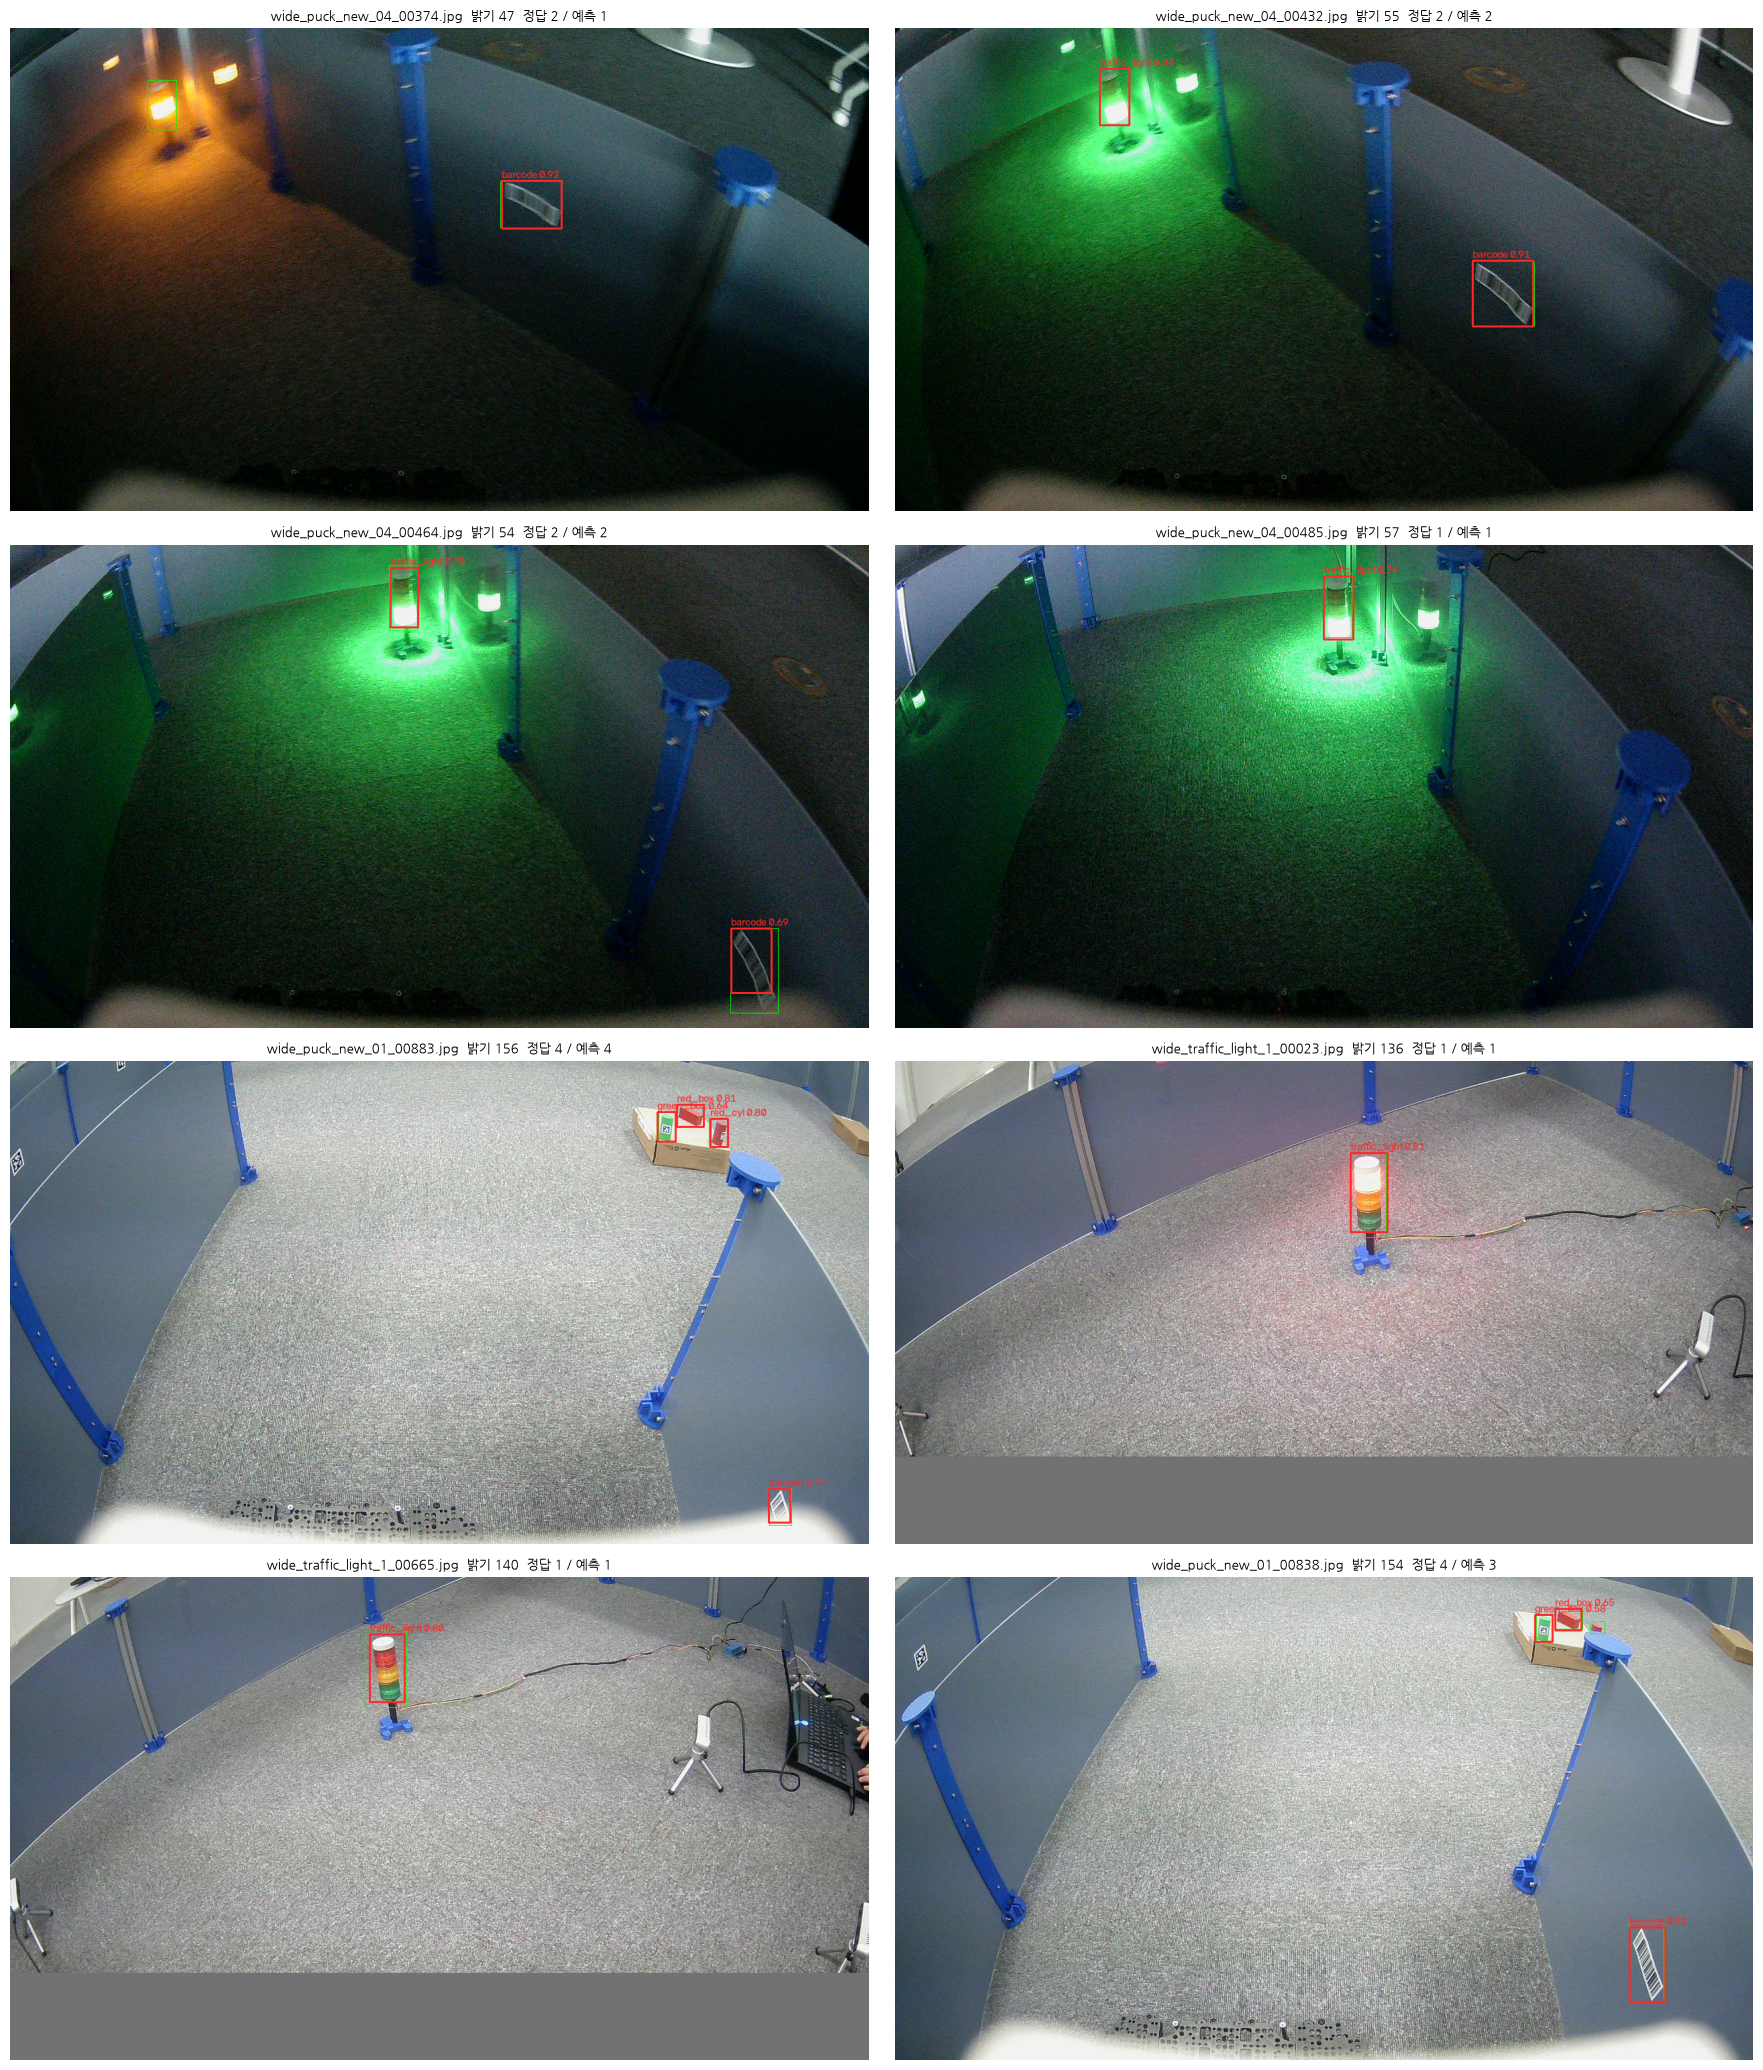

In [8]:
import random
N_SHOW, SEED = 8, 0
model = YOLO(str(WEIGHTS['2단계 (최종)']))
dark = groups['어두움'][:N_SHOW // 2]
rest = [p for p in test_imgs if p not in dark]
random.Random(SEED).shuffle(rest)
imgs = dark + rest[:N_SHOW - len(dark)]

ncol = 2; nrow = (len(imgs) + ncol - 1) // ncol
fig, axes = plt.subplots(nrow, ncol, figsize=(9 * ncol, 5.2 * nrow), squeeze=False)
for ax, p, r in zip(axes.flat, imgs, model.predict([str(x) for x in imgs], conf=CONF, imgsz=IMGSZ, verbose=False)):
    im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    h, w = im.shape[:2]
    gts = read_gt(p, w, h)
    for c_, (x0, y0, x1, y1) in gts:
        cv2.rectangle(im, (int(x0), int(y0)), (int(x1), int(y1)), (0, 255, 0), 1)
    for (x0, y0, x1, y1), c_, s in zip(r.boxes.xyxy.tolist(), r.boxes.cls.tolist(), r.boxes.conf.tolist()):
        cv2.rectangle(im, (int(x0), int(y0)), (int(x1), int(y1)), (255, 40, 40), 2)
        cv2.putText(im, f'{CLASSES[int(c_)]} {s:.2f}', (int(x0), max(14, int(y0) - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 40, 40), 1)
    ax.imshow(im); ax.axis('off')
    ax.set_title(f'{p.name}  밝기 {bri[p.name]:.0f}  정답 {len(gts)} / 예측 {len(r.boxes)}', fontsize=9)
for ax in list(axes.flat)[len(imgs):]:
    ax.axis('off')
plt.tight_layout(); plt.show()
